<a href="https://colab.research.google.com/github/ddev3r/Machine-learning/blob/main/%D0%A1%D1%82%D0%B0%D1%80%D0%BE%D0%B2%D0%BE%D0%B9%D1%82%D0%BE%D0%B2_%D0%9F%D0%A0_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Варіант 20**

**Завдання №1**

In [1]:
# Підключення потрібних бібліотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Бібліотеки успішно підключено!")
print("Версія Pandas:", pd.__version__)

Бібліотеки успішно підключено!
Версія Pandas: 2.2.3


In [2]:
# Завантаження датасету ВВП із Вікіпедії
import pandas as pd
import requests
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/131.0.0.0 Safari/537.36"
    )
}
response = requests.get(url, headers=headers, timeout=30)

print("Код відповіді сервера:", response.status_code)

response.raise_for_status()

# Зчитуємо таблиці
tables = pd.read_html(StringIO(response.text))

print("Кількість знайдених таблиць:", len(tables))

for i, table in enumerate(tables):
    print(f"\nТаблиця {i}:")
    print(table.columns)
    display(table.head(2))

Код відповіді сервера: 200
Кількість знайдених таблиць: 8

Таблиця 0:
Index([0], dtype='int64')


,0
0,Largest economies in the world by nominal GDP ...



Таблиця 1:
Index([0, 1], dtype='int64')


,0,1
0,> $20 trillion $10–20 trillion $5–10 trillio...,$250–500 billion $100–250 billion $50–100 bi...



Таблиця 2:
Index(['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]'], dtype='object')


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000


... (6 outputs left out)


Таблиця 6:
Index(['vteEconomic classification of countries', 'vteEconomic classification of countries.1'], dtype='object')


,vteEconomic classification of countries,vteEconomic classification of countries.1
0,Developed country Advanced economy Developing ...,Developed country Advanced economy Developing ...
1,Three/Four-World Model,First World Second World Third World Fourth World



Таблиця 7:
Index([0, 1], dtype='int64')


,0,1
0,Nominal,By country past and projected per capita per c...
1,Purchasing power parity (PPP),By country future estimates per capita per cap...


In [3]:
# Шукаємо таблицю з потрібними даними МВФ, Світового банку та ООН
def normalize_name(value):
    return str(value).lower().replace("\n", " ").strip()


def find_gdp_table(tables):
    for i, table in enumerate(tables):
        # Перетворюємо заголовки на текст для пошуку
        if isinstance(table.columns, pd.MultiIndex):
            column_names = [
                " ".join(str(part) for part in col if "Unnamed" not in str(part))
                for col in table.columns
            ]
        else:
            column_names = [str(col) for col in table.columns]

        normalized = [normalize_name(col) for col in column_names]
        joined = " ".join(normalized)

        has_country = "country" in joined
        has_imf = "imf" in joined or "international monetary fund" in joined
        has_world_bank = "world bank" in joined
        has_un = "united nations" in joined or "un " in joined

        if has_country and has_imf and has_world_bank and has_un:
            print("Знайдено відповідну таблицю:", i)
            return table.copy()

    raise ValueError(
        "Не вдалося автоматично знайти таблицю. "
        "Переглянь результати попередньої комірки."
    )


gdp_raw = find_gdp_table(tables)


print("\nПочаткові назви стовпців:")
print(gdp_raw.columns)

display(gdp_raw.head())

Знайдено відповідну таблицю: 2

Початкові назви стовпців:
Index(['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]'], dtype='object')


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


In [4]:
# Підганяємо назви стовпців
if isinstance(gdp_raw.columns, pd.MultiIndex):
    gdp_raw.columns = [
        " ".join(str(part) for part in col if "Unnamed" not in str(part)).strip()
        for col in gdp_raw.columns
    ]

print("Поточні назви стовпців:")
for col in gdp_raw.columns:
    print(col)

Поточні назви стовпців:
Country/Territory
IMF (2026)[1]
World Bank (2025)[6]
United Nations (2024)[7]


In [5]:
# Шукаємо потрібні стовпці за назвами
columns = list(gdp_raw.columns)

def find_column(columns, required_words):
    for col in columns:
        name = normalize_name(col)
        if all(word in name for word in required_words):
            return col
    return None


country_col = find_column(columns, ["country"])
imf_col = find_column(columns, ["imf"])
wb_col = find_column(columns, ["world bank"])
un_col = find_column(columns, ["united nations"])

print("Країна:", country_col)
print("МВФ:", imf_col)
print("Світовий банк:", wb_col)
print("ООН:", un_col)

Країна: Country/Territory
МВФ: IMF (2026)[1]
Світовий банк: World Bank (2025)[6]
ООН: United Nations (2024)[7]


№1 Вивести перших 5 рядків.

In [7]:
print("Перші 5 рядків датасету:")
gdp = gdp_raw[[country_col, imf_col, wb_col, un_col]].copy()
display(gdp.head(5))

Перші 5 рядків датасету:


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


№2 Визначити розмір датасета.

In [8]:
print("Розмір датасету:", gdp.shape)
print("Кількість рядків:", gdp.shape[0])
print("Кількість стовпців:", gdp.shape[1])

Розмір датасету: (222, 4)
Кількість рядків: 222
Кількість стовпців: 4


№3 Визначити оптимальну кількість стовпців.

In [10]:
print("Усі стовпці:", list(gdp.columns))
print("Кількість стовпців:", len(gdp.columns))

required_columns = [
    "Country/Territory",
    "IMF (2026)[1]",
    "World Bank (2025)[6]",
    "United Nations (2024)[7]"
]

gdp = gdp[required_columns]

print("Кількість стовпців після оптимізації:", len(gdp.columns))
display(gdp.head())

Усі стовпці: ['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']
Кількість стовпців: 4
Кількість стовпців після оптимізації: 4


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


№4 Змінити назви стовпців на більш зручні, наприклад
Country MVF_2024 WorldBank_2023 OON_2022

In [11]:
# Перейменування стовпців
if any(col is None for col in [country_col, imf_col, wb_col, un_col]):
    raise ValueError(
        "Не знайдено всі потрібні стовпці. "
        "Перевір їхні назви в попередній комірці."
    )

gdp = gdp_raw[[country_col, imf_col, wb_col, un_col]].copy()

gdp.columns = [
    "Country",
    "MVF_2024",
    "WorldBank_2023",
    "OON_2022"
]

display(gdp.head())

,Country,MVF_2024,WorldBank_2023,OON_2022
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


№5 Визначити тип даних.

In [12]:
print("Типи даних:")
print(gdp.dtypes)

print("\nЗагальна інформація про датасет:")
gdp.info()

Типи даних:
Country           object
MVF_2024          object
WorldBank_2023    object
OON_2022          object
dtype: object

Загальна інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222 entries, 0 to 221
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Country         222 non-null    object
 1   MVF_2024        222 non-null    object
 2   WorldBank_2023  222 non-null    object
 3   OON_2022        222 non-null    object
dtypes: object(4)
memory usage: 7.1+ KB


№6 Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [13]:
# Заміна тире
gdp = gdp.replace(
    ["—", "–", "-", "−", ""],
    np.nan
)

numeric_columns = [
    "MVF_2024",
    "WorldBank_2023",
    "OON_2022"
]

# Перетворення значень на числа
for col in numeric_columns:
    gdp[col] = (
        gdp[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.strip()
    )

    gdp[col] = pd.to_numeric(gdp[col], errors="coerce")

print("Типи даних після перетворення:")
print(gdp.dtypes)

print("\nКількість пропущених значень до заповнення:")
print(gdp.isna().sum())

Типи даних після перетворення:
Country            object
MVF_2024          float64
WorldBank_2023    float64
OON_2022          float64
dtype: object

Кількість пропущених значень до заповнення:
Country            0
MVF_2024          30
WorldBank_2023    35
OON_2022           9
dtype: int64


In [15]:
# Заповнення пропусків середнім значенням кожного стовпця
for col in numeric_columns:
    mean_value = gdp[col].mean()
    gdp[col] = gdp[col].fillna(mean_value)

print("Кількість пропущених значень після заповнення:")
print(gdp.isna().sum())

Кількість пропущених значень після заповнення:
Country           0
MVF_2024          0
WorldBank_2023    0
OON_2022          0
dtype: int64


№7 Ще раз перевірити наявність пропущених значень.

In [14]:
print("Перевірка пропусків:")
print(gdp.isna().sum())

print("\nЧи є пропущені значення в датасеті?")
print(gdp.isna().any().any())

Перевірка пропусків:
Country            0
MVF_2024          30
WorldBank_2023    35
OON_2022           9
dtype: int64

Чи є пропущені значення в датасеті?
True


№8 Перевірити наявність дублікатів. При наявності видалити дублікати.

In [16]:
print("Кількість дублікатів до видалення:", gdp.duplicated().sum())

gdp = gdp.drop_duplicates().reset_index(drop=True)

print("Кількість дублікатів після видалення:", gdp.duplicated().sum())
print("Розмір датасету після очищення:", gdp.shape)

Кількість дублікатів до видалення: 0
Кількість дублікатів після видалення: 0
Розмір датасету після очищення: (222, 4)


№9 Вивести описову статистику датасету describe()

In [17]:
print("Описова статистика показників ВВП:")
display(gdp[numeric_columns].describe())

Описова статистика показників ВВП:


,MVF_2024,WorldBank_2023,OON_2022
count,2.220000e+02,2.220000e+02,2.220000e+02
mean,1.332231e+06,1.255590e+06,1.043818e+06
std,8.959482e+06,8.288461e+06,7.830341e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.932375e+04,2.003400e+04,9.170750e+03
50%,1.039745e+05,9.986350e+04,4.322450e+04
75%,7.465068e+05,1.041520e+06,3.048545e+05
max,1.280038e+08,1.183502e+08,1.115651e+08


№10 Визначте відхилення (різницю) між показниками MVF_2024 та
WorldBank_2023 для кожної країни. У яких країнах ці показники
найбільше відрізняються (дати відповідь)?

In [18]:
# Обчислення різниці між показниками
gdp["Difference"] = gdp["MVF_2024"] - gdp["WorldBank_2023"]

# Абсолютна різниця без урахування знака
gdp["Absolute_Difference"] = gdp["Difference"].abs()

print("Країни з найбільшими відмінностями показників:")

display(
    gdp[["Country", "MVF_2024", "WorldBank_2023",
         "Difference", "Absolute_Difference"]]
    .sort_values("Absolute_Difference", ascending=False)
    .head(10)
)

largest_difference = gdp.loc[gdp["Absolute_Difference"].idxmax()]

print("\nНайбільша абсолютна різниця:")
print("Країна:", largest_difference["Country"])
print("МВФ:", largest_difference["MVF_2024"])
print("Світовий банк:", largest_difference["WorldBank_2023"])
print("Різниця:", largest_difference["Difference"])
print("Абсолютна різниця:", largest_difference["Absolute_Difference"])

Країни з найбільшими відмінностями показників:


,Country,MVF_2024,WorldBank_2023,Difference,Absolute_Difference
0,World,1.280038e+08,1.183502e+08,9.653610e+06,9.653610e+06
2,China[n 1],2.154640e+07,1.949804e+07,2.048364e+06,2.048364e+06
1,United States,3.264237e+07,3.076970e+07,1.872673e+06,1.872673e+06
197,Sint Maarten,1.332231e+06,1.888000e+03,1.330343e+06,1.330343e+06
146,Palestine[n 11][n 12],1.332231e+06,1.716700e+04,1.315064e+06,1.315064e+06
192,San Marino,2.417000e+03,1.255590e+06,-1.253173e+06,1.253173e+06
179,Aruba,4.671000e+03,1.255590e+06,-1.250919e+06,1.250919e+06
172,South Sudan,6.069000e+03,1.255590e+06,-1.249521e+06,1.249521e+06
168,Yemen,7.435000e+03,1.255590e+06,-1.248155e+06,1.248155e+06
159,Liechtenstein,9.442000e+03,1.255590e+06,-1.246148e+06,1.246148e+06



Найбільша абсолютна різниця:
Країна: World
МВФ: 128003776.0
Світовий банк: 118350166.0
Різниця: 9653610.0
Абсолютна різниця: 9653610.0


№11 Обчисліть кореляцію між показниками MVF_2024, WorldBank_2023 та
OON_2022. Які пари змінних мають найвищу кореляцію?



In [19]:
correlation = gdp[numeric_columns].corr()

print("Матриця кореляції:")
display(correlation)

# Визначаємо пари змінних
pairs = [
    ("MVF_2024", "WorldBank_2023"),
    ("MVF_2024", "OON_2022"),
    ("WorldBank_2023", "OON_2022")
]

results = []

for col1, col2 in pairs:
    results.append({
        "Пара змінних": f"{col1} — {col2}",
        "Кореляція": correlation.loc[col1, col2],
        "Абсолютна кореляція": abs(correlation.loc[col1, col2])
    })

correlation_results = pd.DataFrame(results)
correlation_results = correlation_results.sort_values(
    "Абсолютна кореляція",
    ascending=False
)

print("Пари змінних за силою кореляції:")
display(correlation_results)

Матриця кореляції:


,MVF_2024,WorldBank_2023,OON_2022
MVF_2024,1.000000,0.999507,0.999007
WorldBank_2023,0.999507,1.000000,0.998864
OON_2022,0.999007,0.998864,1.000000


Пари змінних за силою кореляції:


,Пара змінних,Кореляція,Абсолютна кореляція
0,MVF_2024 — WorldBank_2023,0.999507,0.999507
1,MVF_2024 — OON_2022,0.999007,0.999007
2,WorldBank_2023 — OON_2022,0.998864,0.998864


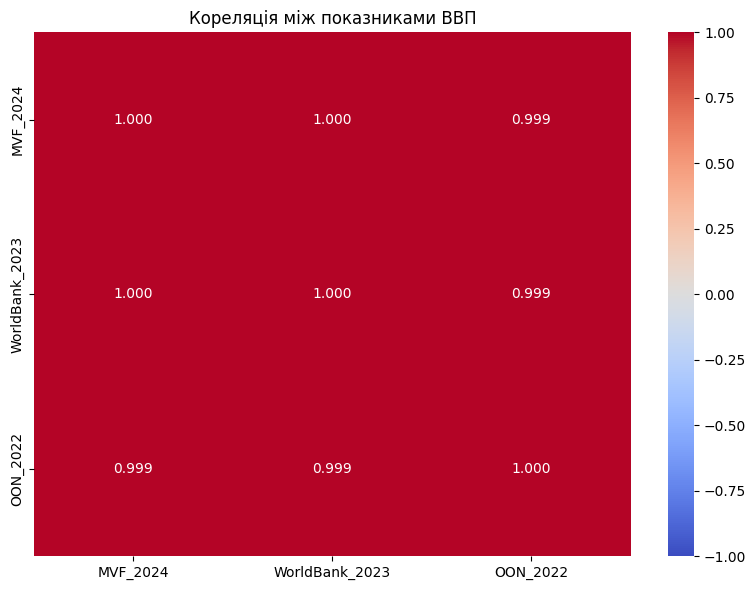

In [20]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)

plt.title("Кореляція між показниками ВВП")
plt.tight_layout()
plt.show()

№12 Обчисліть середнє значення для кожного стовпця (MVF_2024,
WorldBank_2023, OON_2022). Як це середнє значення змінюється між
роками?


In [21]:
mean_gdp = gdp[numeric_columns].mean()

print("Середнє значення показників ВВП:")
display(mean_gdp.to_frame(name="Середнє значення"))

print("\nПорівняння середніх значень:")
print(f"MVF_2024: {mean_gdp['MVF_2024']:,.2f} млн дол. США")
print(f"WorldBank_2023: {mean_gdp['WorldBank_2023']:,.2f} млн дол. США")
print(f"OON_2022: {mean_gdp['OON_2022']:,.2f} млн дол. США")

Середнє значення показників ВВП:


,Середнє значення
MVF_2024,1.332231e+06
WorldBank_2023,1.255590e+06
OON_2022,1.043818e+06



Порівняння середніх значень:
MVF_2024: 1,332,230.74 млн дол. США
WorldBank_2023: 1,255,590.42 млн дол. США
OON_2022: 1,043,818.22 млн дол. США


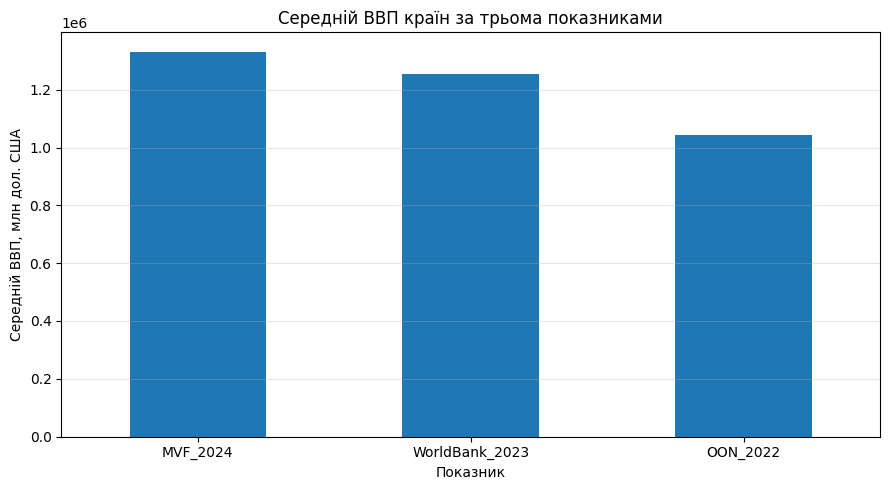

In [22]:
plt.figure(figsize=(9, 5))

mean_gdp.plot(kind="bar")

plt.title("Середній ВВП країн за трьома показниками")
plt.xlabel("Показник")
plt.ylabel("Середній ВВП, млн дол. США")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№13 Обчисліть стандартне відхилення показників для кожної країни. Яка
країна має найвищу варіативність у показниках між роками?

In [23]:
gdp["Standard_Deviation"] = gdp[numeric_columns].std(axis=1)

print("Країни з найбільшим стандартним відхиленням:")

display(
    gdp[["Country"] + numeric_columns + ["Standard_Deviation"]]
    .sort_values("Standard_Deviation", ascending=False)
    .head(10)
)

most_variable = gdp.loc[gdp["Standard_Deviation"].idxmax()]

print("\nКраїна з найбільшим стандартним відхиленням:")
print(most_variable["Country"])
print("Стандартне відхилення:", most_variable["Standard_Deviation"])

Країни з найбільшим стандартним відхиленням:


,Country,MVF_2024,WorldBank_2023,OON_2022,Standard_Deviation
0,World,1.280038e+08,1.183502e+08,111565144.0,8.260925e+06
1,United States,3.264237e+07,3.076970e+07,29298000.0,1.676188e+06
2,China[n 1],2.154640e+07,1.949804e+07,18743802.0,1.450244e+06
197,Sint Maarten,1.332231e+06,1.888000e+03,1670.0,7.681367e+05
146,Palestine[n 11][n 12],1.332231e+06,1.716700e+04,16017.0,7.595846e+05
220,Montserrat,1.332231e+06,1.255590e+06,81.0,7.479751e+05
215,Cook Islands,1.332231e+06,1.255590e+06,414.0,7.477831e+05
214,Anguilla,1.332231e+06,1.255590e+06,456.0,7.477589e+05
201,Turks and Caicos Islands,1.332231e+06,1.255590e+06,1757.0,7.470087e+05
199,British Virgin Islands,1.332231e+06,1.255590e+06,1830.0,7.469667e+05



Країна з найбільшим стандартним відхиленням:
World
Стандартне відхилення: 8260925.408249853


№14 Визначення країни з найвищим та найнижчим показниками: Знайдіть
країну з найвищим та найнижчим показниками у кожному з років
(MVF_2024, WorldBank_2023, OON_2022).

In [31]:
for col in numeric_columns:

    max_idx = gdp[col].idxmax()
    max_country = gdp.loc[max_idx, "Country"]
    max_value = gdp.loc[max_idx, col]

    min_idx = gdp[col].idxmin()
    min_country = gdp.loc[min_idx, "Country"]
    min_value = gdp.loc[min_idx, col]

    print(f"\nПоказник {col}:")
    print(f"Найвищий: {max_country} — {max_value:,.2f} млн дол. США")
    print(f"Найнижчий: {min_country} — {min_value:,.2f} млн дол. США")


Показник MVF_2024:
Найвищий: World — 128,003,776.00 млн дол. США
Найнижчий: Tuvalu — 65.00 млн дол. США

Показник WorldBank_2023:
Найвищий: World — 118,350,166.00 млн дол. США
Найнижчий: Tuvalu — 57.00 млн дол. США

Показник OON_2022:
Найвищий: World — 111,565,144.00 млн дол. США
Найнижчий: Tuvalu — 56.00 млн дол. США


№15 Побудуйте гістограму для розподілу показників MVF_2024 серед всіх
країн. Який вигляд має розподіл? Чи є країни, що виділяються?

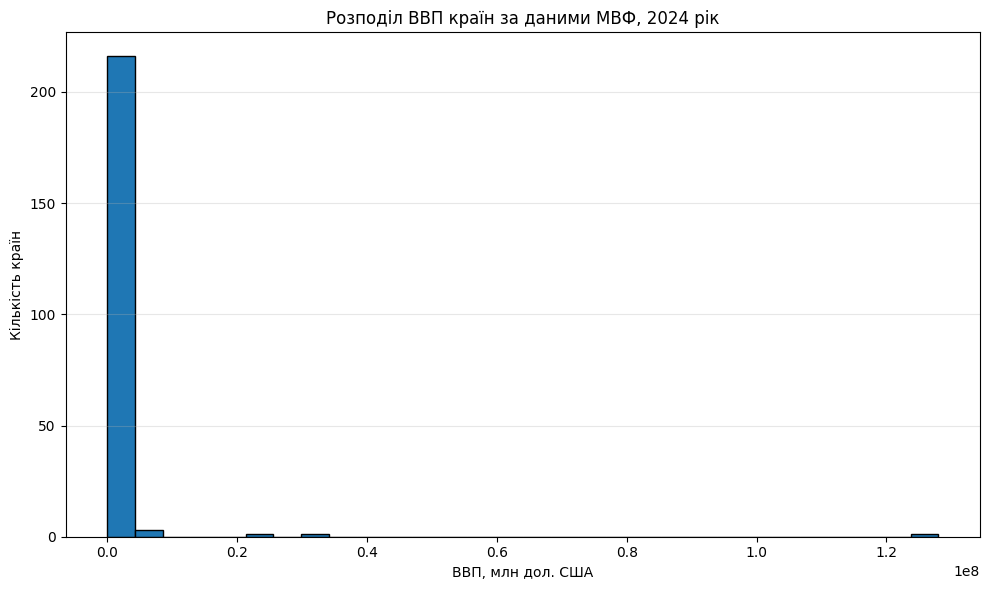

In [25]:
plt.figure(figsize=(10, 6))

plt.hist(
    gdp["MVF_2024"],
    bins=30,
    edgecolor="black"
)

plt.title("Розподіл ВВП країн за даними МВФ, 2024 рік")
plt.xlabel("ВВП, млн дол. США")
plt.ylabel("Кількість країн")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

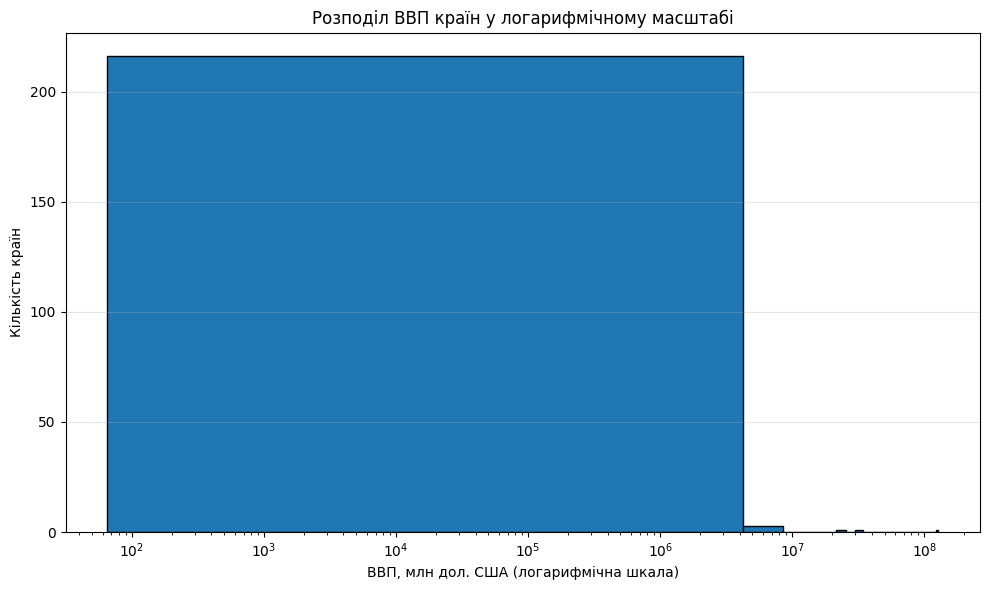

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(
    gdp["MVF_2024"],
    bins=30,
    edgecolor="black"
)

plt.xscale("log")

plt.title("Розподіл ВВП країн у логарифмічному масштабі")
plt.xlabel("ВВП, млн дол. США (логарифмічна шкала)")
plt.ylabel("Кількість країн")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№16 Розрахуйте частку кожної країни в загальному значенні для кожного
року (MVF_2024, WorldBank_2023, OON_2022). Як змінюються частки
країн з часом (дати відповідь)?

In [27]:
for col in numeric_columns:
    share_col = col + "_Share_Percent"

    total = gdp[col].sum()

    gdp[share_col] = gdp[col] / total * 100

    print(f"\nЧастки країн за показником {col}:")
    print("Загальне значення:", f"{total:,.2f}", "млн дол. США")

    display(
        gdp[["Country", col, share_col]]
        .sort_values(share_col, ascending=False)
        .head(10)
    )


Частки країн за показником MVF_2024:
Загальне значення: 295,755,225.34 млн дол. США


,Country,MVF_2024,MVF_2024_Share_Percent
0,World,128003776.0,43.280309
1,United States,32642373.0,11.036956
2,China[n 1],21546403.0,7.285215
3,Germany,5471299.0,1.849942
4,Japan,4341986.0,1.468101
5,United Kingdom,4268446.0,1.443236
6,India,4060207.0,1.372827
7,France,3554155.0,1.201722
8,Russia,2861156.0,0.967407
9,Italy,2701737.0,0.913504



Частки країн за показником WorldBank_2023:
Загальне значення: 278,741,073.79 млн дол. США


,Country,WorldBank_2023,WorldBank_2023_Share_Percent
0,World,118350166.0,42.458818
1,United States,30769700.0,11.038811
2,China[n 1],19498039.0,6.995036
3,Germany,5050923.0,1.812048
4,Japan,4435163.0,1.591141
5,United Kingdom,4002588.0,1.435952
6,India,3956067.0,1.419262
7,France,3366316.0,1.207686
8,Russia,2561310.0,0.918885
9,Italy,2551557.0,0.915386



Частки країн за показником OON_2022:
Загальне значення: 231,727,643.94 млн дол. США


,Country,OON_2022,OON_2022_Share_Percent
0,World,111565144.0,48.144944
1,United States,29298000.0,12.643291
2,China[n 1],18743802.0,8.088721
3,Germany,4659929.0,2.010951
4,Japan,4026211.0,1.737475
6,India,3952244.0,1.705556
5,United Kingdom,3685881.0,1.590609
7,France,3160443.0,1.363861
9,Italy,2380825.0,1.027424
11,Canada,2270076.0,0.979631


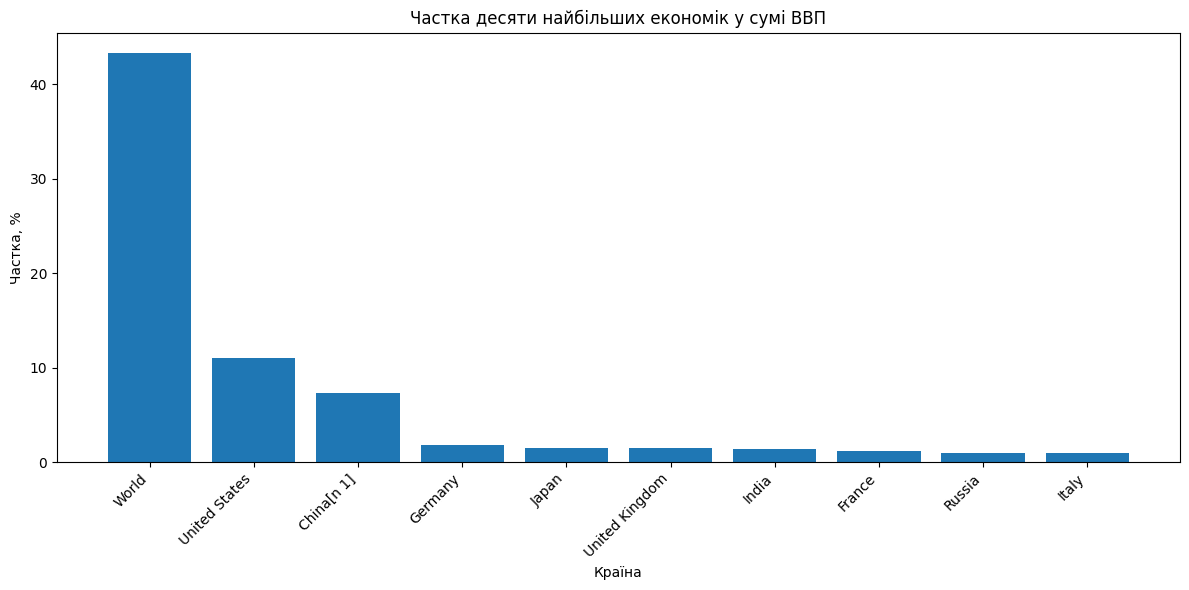

In [28]:
top10 = gdp.nlargest(10, "MVF_2024").copy()

plt.figure(figsize=(12, 6))

plt.bar(
    top10["Country"],
    top10["MVF_2024_Share_Percent"]
)

plt.title("Частка десяти найбільших економік у сумі ВВП")
plt.xlabel("Країна")
plt.ylabel("Частка, %")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [29]:
share_columns = [
    "MVF_2024_Share_Percent",
    "WorldBank_2023_Share_Percent",
    "OON_2022_Share_Percent"
]

for col in share_columns:
    print(f"\nНайбільші частки за показником {col}:")
    display(
        gdp[["Country", col]]
        .sort_values(col, ascending=False)
        .head(5)
    )


Найбільші частки за показником MVF_2024_Share_Percent:


,Country,MVF_2024_Share_Percent
0,World,43.280309
1,United States,11.036956
2,China[n 1],7.285215
3,Germany,1.849942
4,Japan,1.468101



Найбільші частки за показником WorldBank_2023_Share_Percent:


,Country,WorldBank_2023_Share_Percent
0,World,42.458818
1,United States,11.038811
2,China[n 1],6.995036
3,Germany,1.812048
4,Japan,1.591141



Найбільші частки за показником OON_2022_Share_Percent:


,Country,OON_2022_Share_Percent
0,World,48.144944
1,United States,12.643291
2,China[n 1],8.088721
3,Germany,2.010951
4,Japan,1.737475


№17 Візуалізуйте зміни в показниках для кожної країни за три роки на
графіку. Які країни показують стабільне зростання або спад (дати
відповідь)?

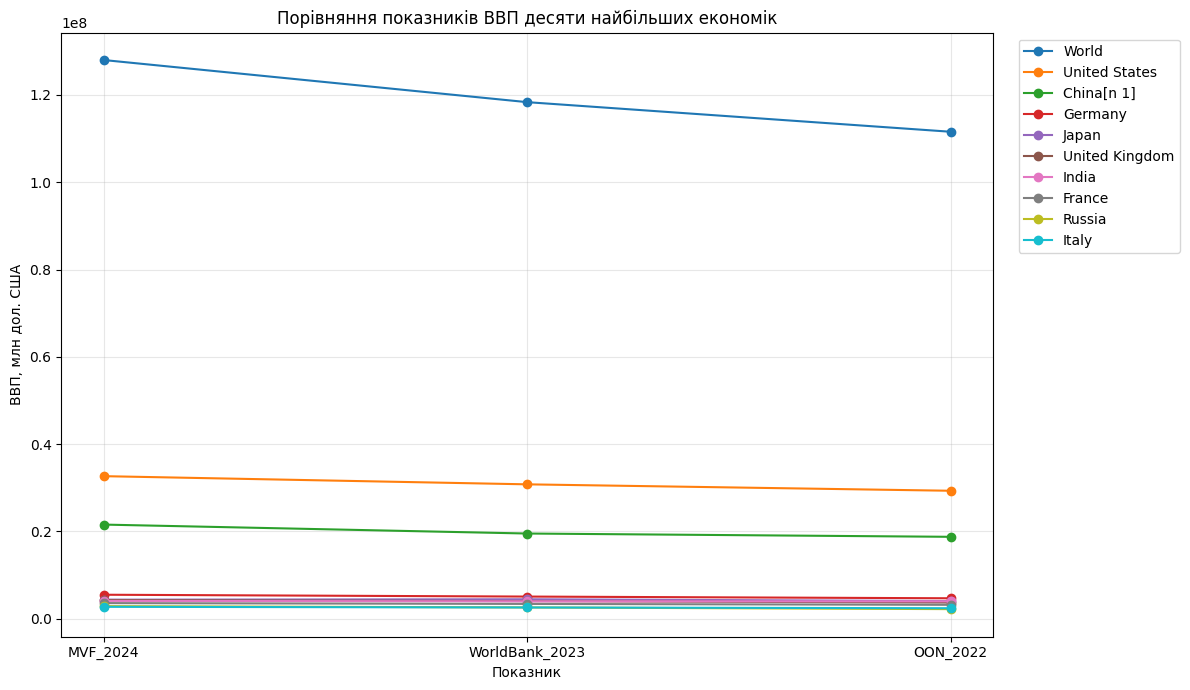

In [30]:
top_countries = gdp.nlargest(10, "MVF_2024").copy()

plot_data = top_countries.set_index("Country")[numeric_columns].T

plt.figure(figsize=(12, 7))

for country in plot_data.columns:
    plt.plot(
        plot_data.index,
        plot_data[country],
        marker="o",
        label=country
    )

plt.title("Порівняння показників ВВП десяти найбільших економік")
plt.xlabel("Показник")
plt.ylabel("ВВП, млн дол. США")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

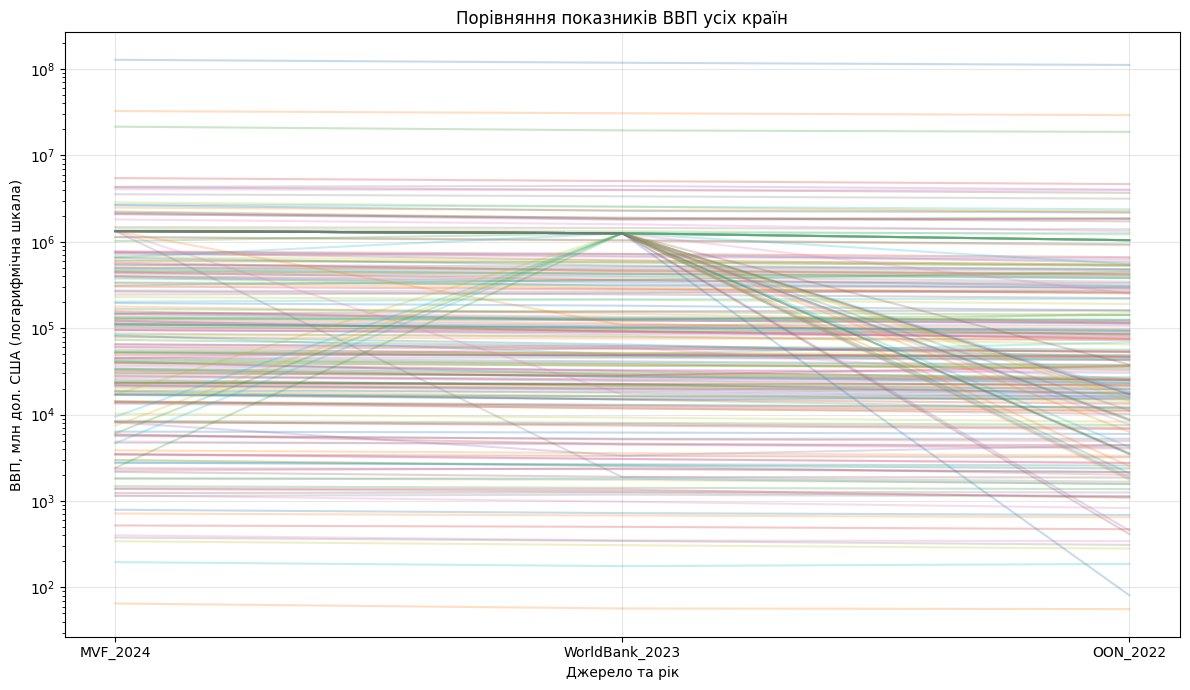

In [32]:
plt.figure(figsize=(12, 7))

for _, row in gdp.iterrows():
    plt.plot(
        ["MVF_2024", "WorldBank_2023", "OON_2022"],
        [row["MVF_2024"], row["WorldBank_2023"], row["OON_2022"]],
        alpha=0.25
    )

plt.yscale("log")
plt.title("Порівняння показників ВВП усіх країн")
plt.xlabel("Джерело та рік")
plt.ylabel("ВВП, млн дол. США (логарифмічна шкала)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
def classify_trend(row):
    values = [
        row["OON_2022"],
        row["WorldBank_2023"],
        row["MVF_2024"]
    ]

    if values[0] < values[1] < values[2]:
        return "Зростання"
    elif values[0] > values[1] > values[2]:
        return "Спад"
    else:
        return "Змішана динаміка"


gdp["Trend"] = gdp.apply(classify_trend, axis=1)

print("Кількість країн за типом зміни показників:")
display(gdp["Trend"].value_counts().to_frame("Кількість країн"))

print("\nКраїни зі зростанням показників:")
display(
    gdp.loc[gdp["Trend"] == "Зростання", ["Country"] + numeric_columns]
)

print("\nКраїни зі спадом показників:")
display(
    gdp.loc[gdp["Trend"] == "Спад", ["Country"] + numeric_columns]
)

Кількість країн за типом зміни показників:


,Кількість країн
Trend,
Зростання,188
Змішана динаміка,30
Спад,4



Країни зі зростанням показників:


,Country,MVF_2024,WorldBank_2023,OON_2022
0,World,1.280038e+08,1.183502e+08,111565144.0
1,United States,3.264237e+07,3.076970e+07,29298000.0
2,China[n 1],2.154640e+07,1.949804e+07,18743802.0
3,Germany,5.471299e+06,5.050923e+06,4659929.0
5,United Kingdom,4.268446e+06,4.002588e+06,3685881.0
...,...,...,...,...
216,Kiribati,4.010000e+02,3.490000e+02,343.0
217,Palau,3.770000e+02,3.450000e+02,310.0
218,Marshall Islands,3.420000e+02,3.080000e+02,281.0
220,Montserrat,1.332231e+06,1.255590e+06,81.0



Країни зі спадом показників:


,Country,MVF_2024,WorldBank_2023,OON_2022
52,Iran,311950.0,362682.0,448092.0
57,Iraq,245234.0,254367.0,279641.0
59,Qatar,203044.0,215560.0,219163.0
65,Kuwait,146911.0,157209.0,160227.0


Висновок

Під час виконання завдання за допомогою бібліотеки Pandas було досліджено датасет номінального ВВП країн за оцінками МВФ, Світового банку та ООН. Дані пройшли повний етап попередньої обробки: відбір та перейменування стовпців, заміну пропусків на середні значення та перевірку на дублікати.

На основі очищених даних було розраховано описову статистику, середні значення, стандартні відхилення та частки кожної країни у загальному ВВП. Аналіз та побудовані візуалізації показали, що найбільшу абсолютну різницю між оцінками МВФ та Світового банку має сумарний світовий ВВП («World»). При цьому показники MVF_2024 та WorldBank_2023 демонструють дуже сильну пряму кореляцію (0,999482).

У результаті було успішно закріплено практичні навички збирання, очищення, аналізу та візуалізації даних. Також встановлено, що для коректної інтерпретації макроекономічних показників необхідно обов'язково враховувати специфіку різних джерел та роки оцінювання.

**Завдання №2**

Завантаження файлу

In [34]:
from google.colab import files

uploaded = files.upload()

Saving titanic (5).csv to titanic (5).csv


In [35]:
import io

uploaded_filename = next(iter(uploaded.keys()))

titanic = pd.read_csv(io.BytesIO(uploaded[uploaded_filename]))

print("Завантажений файл:", uploaded_filename)
print("Датасет успішно завантажено!")

Завантажений файл: titanic (5).csv
Датасет успішно завантажено!


№1 Вивести перших 5 рядків.

In [36]:
print("Перші 5 рядків датасету Titanic:")
display(titanic.head(5))

Перші 5 рядків датасету Titanic:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


№2 Визначити розмір датасета.

In [38]:
print("Розмір датасету:", titanic.shape)
print("Кількість пасажирів:", titanic.shape[0])
print("Кількість стовпців:", titanic.shape[1])

Розмір датасету: (891, 12)
Кількість пасажирів: 891
Кількість стовпців: 12


№3 Визначити тип даних.

In [39]:
print("Типи даних:")
print(titanic.dtypes)

print("\nЗагальна інформація:")
titanic.info()

Типи даних:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Загальна інформація:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non

№4 Визначити наявність пропущених значень. При наявності, замінити
пропущені значення на середнє значення.

In [40]:
print("Кількість пропущених значень у кожному стовпці:")
print(titanic.isna().sum())

print("\nВідсоток пропущених значень:")
print((titanic.isna().mean() * 100).round(2))

Кількість пропущених значень у кожному стовпці:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Відсоток пропущених значень:
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


In [42]:
numeric_cols = titanic.select_dtypes(include="number").columns.tolist()

print("Числові стовпці:", numeric_cols)

# Заповнюємо пропуски
for col in numeric_cols:
    if titanic[col].isna().any():
        titanic[col] = titanic[col].fillna(titanic[col].mean())

print("\nПропуски після заповнення числових стовпців:")
print(titanic.isna().sum())

Числові стовпці: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Пропуски після заповнення числових стовпців:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64




№5 Ще раз перевірити наявність пропущених значень.

In [43]:
print("Кількість пропусків після обробки:")
print(titanic.isna().sum())

print("\nЧи залишилися пропущені значення?")
print(titanic.isna().any().any())

Кількість пропусків після обробки:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Чи залишилися пропущені значення?
True


№6 Перевірити наявність дублікатів. При наявності видалити дублікати.

In [44]:
print("Кількість дублікатів до видалення:", titanic.duplicated().sum())

titanic = titanic.drop_duplicates().reset_index(drop=True)

print("Кількість дублікатів після видалення:", titanic.duplicated().sum())
print("Розмір датасету після видалення дублікатів:", titanic.shape)

Кількість дублікатів до видалення: 0
Кількість дублікатів після видалення: 0
Розмір датасету після видалення дублікатів: (891, 12)


№7 Вивести описову статистику датасету describe()

In [45]:
print("Описова статистика числових стовпців:")
display(titanic.describe())

Описова статистика числових стовпців:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


№8 Видалити стовпчик Cabin

In [46]:
if "Cabin" in titanic.columns:
    titanic = titanic.drop(columns=["Cabin"])

print("Стовпець Cabin видалено.")
print("Поточні стовпці:")
print(titanic.columns.tolist())

Стовпець Cabin видалено.
Поточні стовпці:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']


№9 Сформувати датасет з обраними стовпцями:
['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]

In [47]:
selected_columns = [
    "Survived",
    "Pclass",
    "Sex",
    "Age",
    "Fare"
]

titanic = titanic[selected_columns].copy()

print("Датасет після вибору стовпців:")
display(titanic.head())

print("\nРозмір нового датасету:", titanic.shape)

Датасет після вибору стовпців:


,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500



Розмір нового датасету: (891, 5)


№10 Замінити бінарні ознаки (Стать) на 0 і 1 (але перевірте унікальні
значення даного стовпчика).

In [48]:
print("Унікальні значення стовпця Sex:")
print(titanic["Sex"].unique())

print("\nКількість записів для кожного значення:")
print(titanic["Sex"].value_counts(dropna=False))

Унікальні значення стовпця Sex:
['male' 'female']

Кількість записів для кожного значення:
Sex
male      577
female    314
Name: count, dtype: int64


In [49]:
#male = 0, female = 1
sex_mapping = {
    "male": 0,
    "female": 1
}

titanic["Sex"] = titanic["Sex"].map(sex_mapping)

print("Унікальні значення Sex після кодування:")
print(titanic["Sex"].unique())

display(titanic.head())

Унікальні значення Sex після кодування:
[0 1]


,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


№11 Ще раз перевірити кількість пропущених даних (впевнитись, що їх
немає).

In [50]:
print("Пропущені значення:")
print(titanic.isna().sum())

print("\nЧи залишилися пропуски?")
print(titanic.isna().any().any())

Пропущені значення:
Survived    0
Pclass      0
Sex         0
Age         0
Fare        0
dtype: int64

Чи залишилися пропуски?
False


№12 Вивести 5 перших рядків датасету.

In [51]:
print("Перші 5 рядків:")
display(titanic.head(5))

Перші 5 рядків:


,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


№13 Вивести 5 останніх рядків датасету.

In [52]:
print("Останні 5 рядків:")
display(titanic.tail(5))

Останні 5 рядків:


,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.000000,13.00
887,1,1,1,19.000000,30.00
888,0,3,1,29.699118,23.45
889,1,1,0,26.000000,30.00
890,0,3,0,32.000000,7.75


№14 Аналіз виживання залежно від статі: Обчисліть відсоток виживання
для кожної статі. Чи була різниця у виживанні між чоловіками та
жінками?

In [53]:
survival_by_sex = (
    titanic.groupby("Sex")["Survived"]
    .mean() * 100
)

survival_by_sex.index = survival_by_sex.index.map({
    0: "Чоловіки",
    1: "Жінки"
})

print("Відсоток виживання залежно від статі:")
display(survival_by_sex.to_frame("Виживання, %"))

Відсоток виживання залежно від статі:


,"Виживання, %"
Sex,
Чоловіки,18.890815
Жінки,74.203822


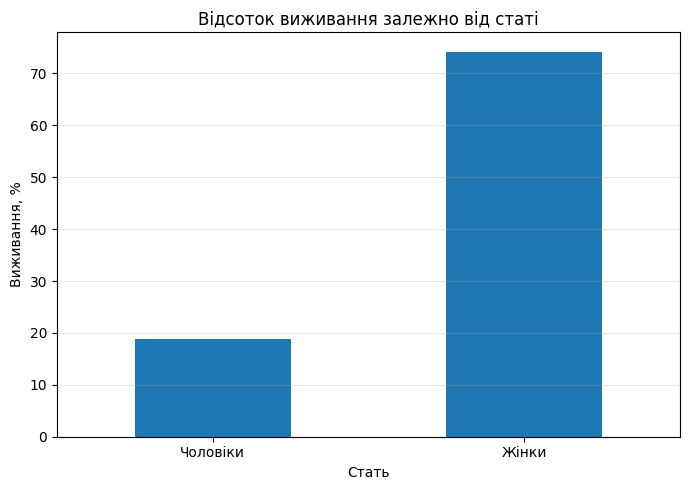

In [54]:
plt.figure(figsize=(7, 5))

survival_by_sex.plot(kind="bar")

plt.title("Відсоток виживання залежно від статі")
plt.xlabel("Стать")
plt.ylabel("Виживання, %")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Є значна різниця у виживанні між чоловіками та жінками

№15 Обчисліть відсоток виживання для кожного класу (Pclass). Який
клас мав найвищий рівень виживання (дати відповідь)?



In [57]:
survival_by_class = (
    titanic.groupby("Pclass")["Survived"]
    .mean() * 100
)

print("Відсоток виживання за класами:")
display(survival_by_class.to_frame("Виживання, %"))

highest_class = survival_by_class.idxmax()

print(
    f"{highest_class} клас мав найвищий відсоток виживання, а саме: "
    f"{survival_by_class.max():.2f}%"
)

Відсоток виживання за класами:


,"Виживання, %"
Pclass,
1,62.962963
2,47.282609
3,24.236253


1 клас мав найвищий відсоток виживання, а саме: 62.96%


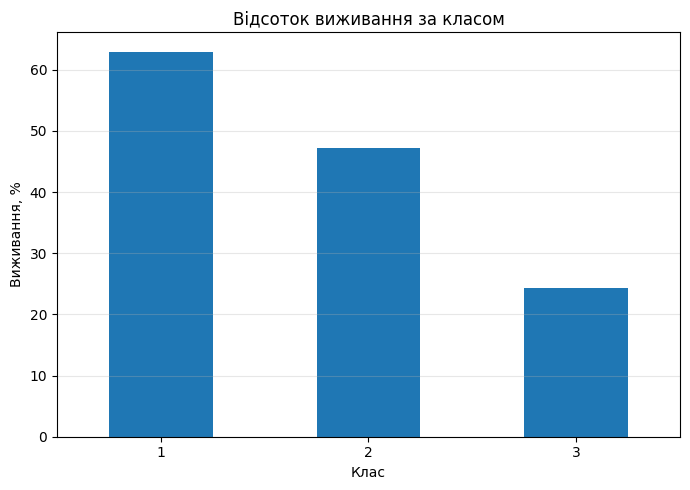

In [56]:
plt.figure(figsize=(7, 5))

survival_by_class.plot(kind="bar")

plt.title("Відсоток виживання за класом")
plt.xlabel("Клас")
plt.ylabel("Виживання, %")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№16 Визначте середній вік тих, хто вижив, і тих, хто не вижив. Чи
впливає вік на виживання (дати відповідь)?

In [60]:
age_by_survival = titanic.groupby("Survived")["Age"].mean()

print("Середній вік пасажирів:")
print(f"Не вижили: {age_by_survival.loc[0]:.2f} років")
print(f"Вижили: {age_by_survival.loc[1]:.2f} років")

Середній вік пасажирів:
Не вижили: 30.42 років
Вижили: 28.55 років


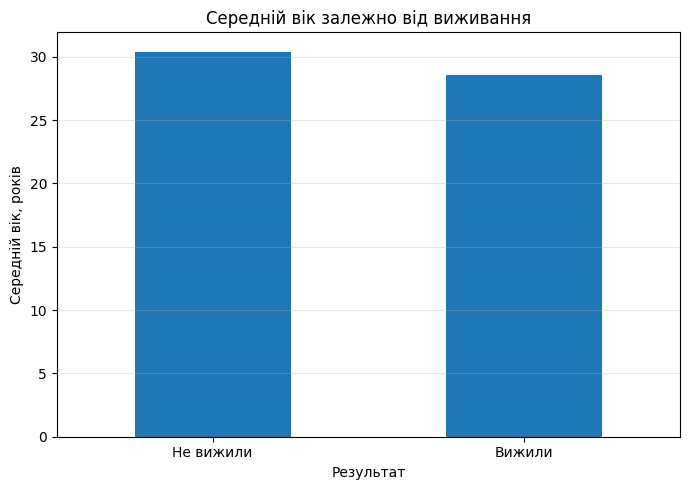

In [61]:
plt.figure(figsize=(7, 5))

age_by_survival.index = age_by_survival.index.map({
    0: "Не вижили",
    1: "Вижили"
})

age_by_survival.plot(kind="bar")

plt.title("Середній вік залежно від виживання")
plt.xlabel("Результат")
plt.ylabel("Середній вік, років")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№17 Розподіліть пасажирів на групи за рівнями тарифів (Fare) і
обчисліть рівень виживання для кожної групи. Як тариф впливав на
шанси виживання (дати відповідь)?

In [62]:
# Створення груп за вартістю квитка
titanic["Fare_Group"] = pd.qcut(
    titanic["Fare"],
    q=4,
    labels=[
        "Низький тариф",
        "Нижче середнього",
        "Вище середнього",
        "Високий тариф"
    ],
    duplicates="drop"
)

# Розрахунок виживання для кожної групи
survival_by_fare = (
    titanic.groupby("Fare_Group", observed=True)["Survived"]
    .agg(["mean", "count"])
)

survival_by_fare["Survival_Percent"] = survival_by_fare["mean"] * 100

print("Виживання залежно від вартості квитка:")
display(survival_by_fare[["count", "Survival_Percent"]])

Виживання залежно від вартості квитка:


,count,Survival_Percent
Fare_Group,,
Низький тариф,223,19.730942
Нижче середнього,224,30.357143
Вище середнього,222,45.495495
Високий тариф,222,58.108108


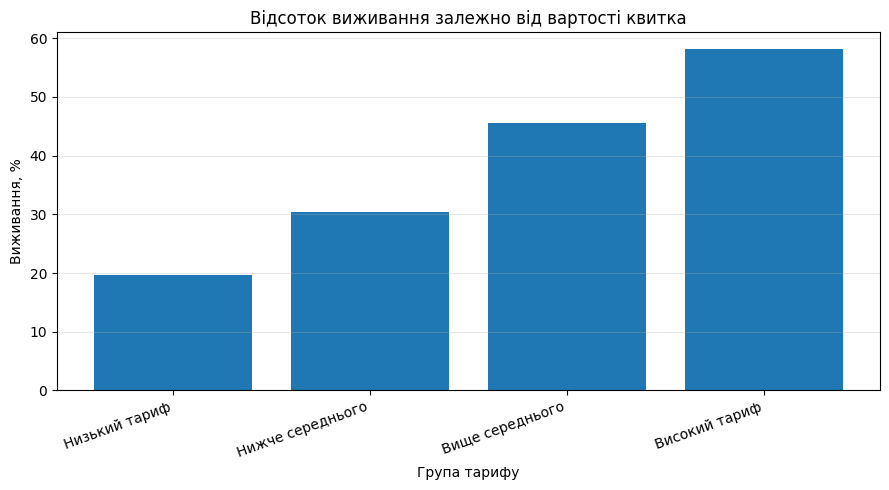

In [63]:
plt.figure(figsize=(9, 5))

plt.bar(
    survival_by_fare.index.astype(str),
    survival_by_fare["Survival_Percent"]
)

plt.title("Відсоток виживання залежно від вартості квитка")
plt.xlabel("Група тарифу")
plt.ylabel("Виживання, %")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Вартість тарифу прямопропорційно впливала на виживання

№18 Аналіз класу та тарифу: Визначте середній тариф (Fare) для кожного
класу (Pclass). Чи існує значна різниця у тарифах між класами (дати
відповідь)?

In [64]:
mean_fare_by_class = titanic.groupby("Pclass")["Fare"].mean()

print("Середня вартість квитка за класами:")
display(mean_fare_by_class.to_frame("Середній тариф"))

for pclass, fare in mean_fare_by_class.items():
    print(f"{pclass}-й клас: {fare:.2f}")

Середня вартість квитка за класами:


,Середній тариф
Pclass,
1,84.154687
2,20.662183
3,13.675550


1-й клас: 84.15
2-й клас: 20.66
3-й клас: 13.68


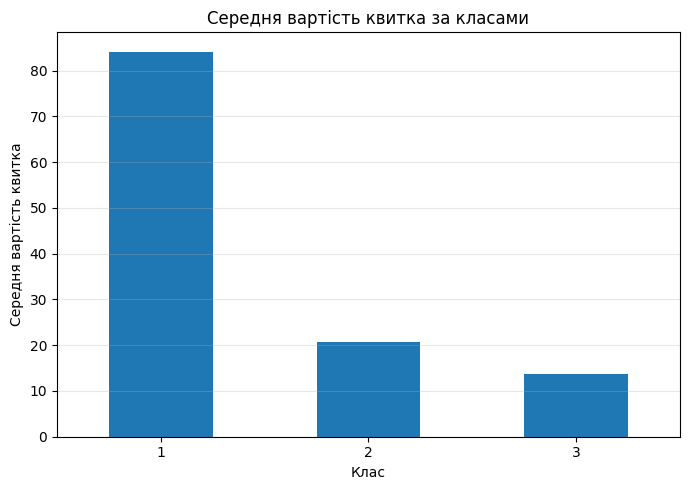

In [65]:
plt.figure(figsize=(7, 5))

mean_fare_by_class.plot(kind="bar")

plt.title("Середня вартість квитка за класами")
plt.xlabel("Клас")
plt.ylabel("Середня вартість квитка")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№19 Обчисліть середній вік пасажирів для кожного класу (Pclass). Як вік
пасажирів розподіляється за класами (дати відповідь)?

In [66]:
mean_age_by_class = titanic.groupby("Pclass")["Age"].mean()

print("Середній вік пасажирів за класами:")
display(mean_age_by_class.to_frame("Середній вік"))

for pclass, age in mean_age_by_class.items():
    print(f"{pclass}-й клас: {age:.2f} років")

Середній вік пасажирів за класами:


,Середній вік
Pclass,
1,37.048118
2,29.866958
3,26.403259


1-й клас: 37.05 років
2-й клас: 29.87 років
3-й клас: 26.40 років


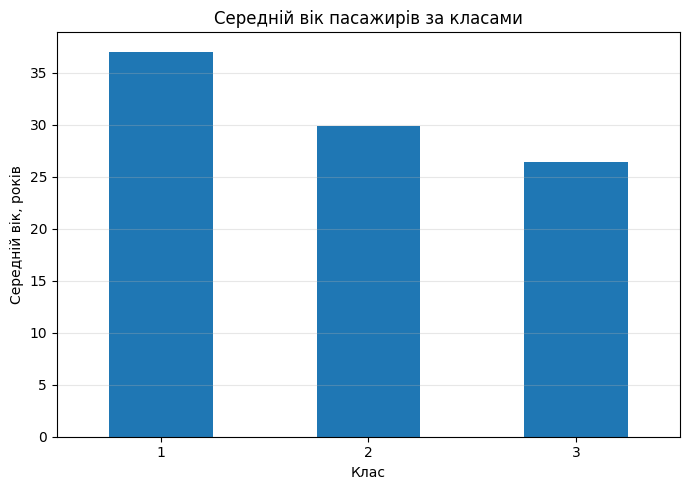

In [67]:
plt.figure(figsize=(7, 5))

mean_age_by_class.plot(kind="bar")

plt.title("Середній вік пасажирів за класами")
plt.xlabel("Клас")
plt.ylabel("Середній вік, років")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№20 Побудуйте гістограму розподілу віку для тих, хто вижив, і тих, хто
не вижив. Чи є видимі відмінності у вікових групах (дати
відповідь)?

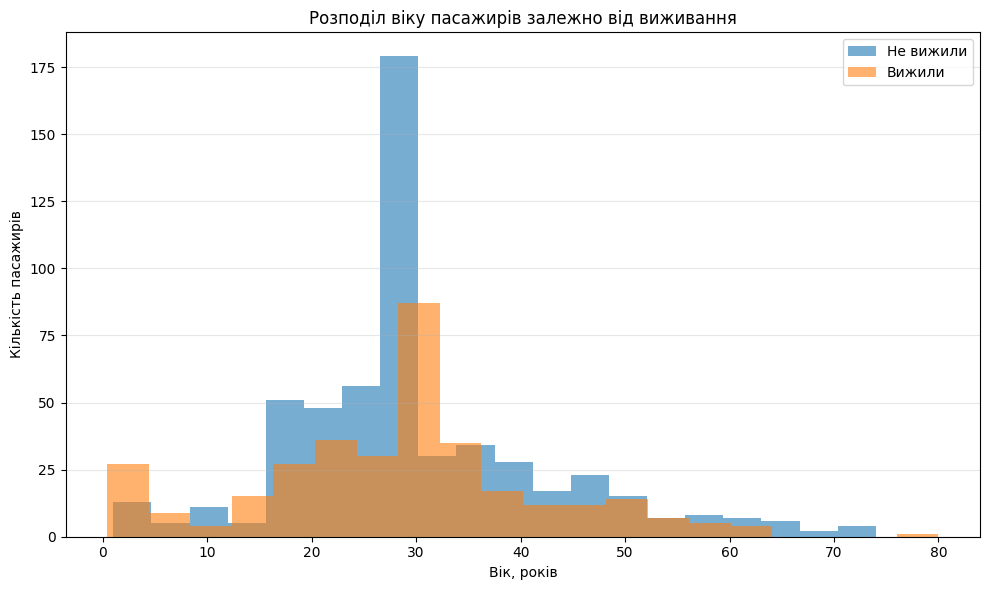

In [68]:
plt.figure(figsize=(10, 6))

plt.hist(
    titanic.loc[titanic["Survived"] == 0, "Age"],
    bins=20,
    alpha=0.6,
    label="Не вижили"
)

plt.hist(
    titanic.loc[titanic["Survived"] == 1, "Age"],
    bins=20,
    alpha=0.6,
    label="Вижили"
)

plt.title("Розподіл віку пасажирів залежно від виживання")
plt.xlabel("Вік, років")
plt.ylabel("Кількість пасажирів")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№21 Обчисліть відсоток виживання для кожної комбінації статі та класу
(наприклад, жінки в 1-му класі, чоловіки в 3-му класі). Яка група
мала найвищий рівень виживання (дати відповідь)?

In [70]:
survival_by_sex_class = (
    titanic.groupby(["Sex", "Pclass"])["Survived"]
    .agg(["mean", "count"])
    .reset_index()
)

survival_by_sex_class["Survival_Percent"] = (
    survival_by_sex_class["mean"] * 100
)

survival_by_sex_class["Sex"] = survival_by_sex_class["Sex"].map({
    0: "Чоловіки",
    1: "Жінки"
})

print("Виживання за статтю та класом:")
display(
    survival_by_sex_class[
        ["Sex", "Pclass", "count", "Survival_Percent"]
    ].sort_values("Survival_Percent", ascending=False)
)

best_group = survival_by_sex_class.loc[
    survival_by_sex_class["Survival_Percent"].idxmax()
]

print("\nГрупа з найвищим рівнем виживання:")
print("Стать:", best_group["Sex"])
print("Клас:", best_group["Pclass"])
print(f"Виживання: {best_group['Survival_Percent']:.2f}%")

Виживання за статтю та класом:


,Sex,Pclass,count,Survival_Percent
3,Жінки,1,94,96.808511
4,Жінки,2,76,92.105263
5,Жінки,3,144,50.000000
0,Чоловіки,1,122,36.885246
1,Чоловіки,2,108,15.740741
2,Чоловіки,3,347,13.544669



Група з найвищим рівнем виживання:
Стать: Жінки
Клас: 1
Виживання: 96.81%


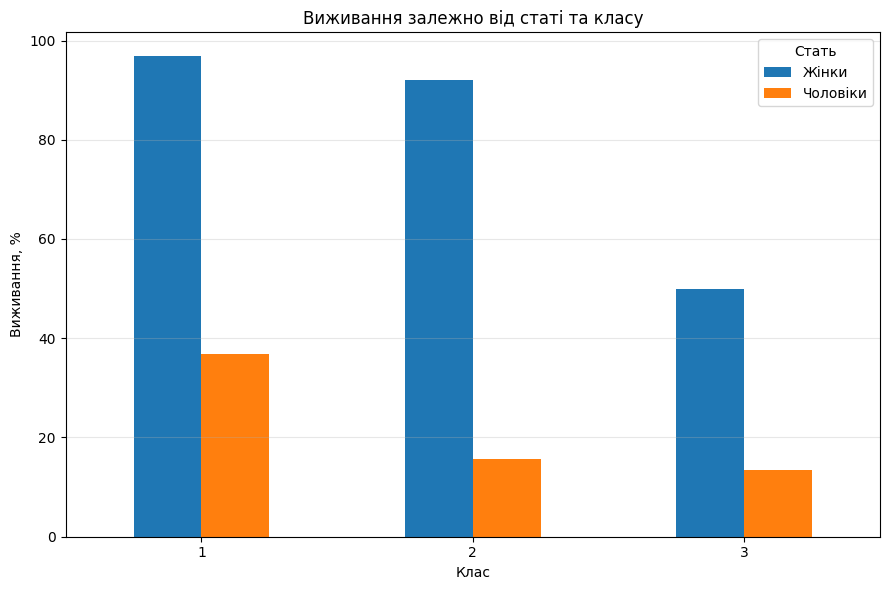

In [71]:
pivot_survival = survival_by_sex_class.pivot(
    index="Pclass",
    columns="Sex",
    values="Survival_Percent"
)

pivot_survival.plot(kind="bar", figsize=(9, 6))

plt.title("Виживання залежно від статі та класу")
plt.xlabel("Клас")
plt.ylabel("Виживання, %")
plt.xticks(rotation=0)
plt.legend(title="Стать")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№22 Обчисліть кореляцію між усіма числовими змінними (Survived,
Pclass, Age, Fare). Які змінні найбільш сильно корелюють з
виживанням (дати відповідь)?

In [72]:
correlation_columns = [
    "Survived",
    "Pclass",
    "Age",
    "Fare"
]

correlation_titanic = titanic[correlation_columns].corr()

print("Матриця кореляції:")
display(correlation_titanic)

Матриця кореляції:


,Survived,Pclass,Age,Fare
Survived,1.000000,-0.338481,-0.069809,0.257307
Pclass,-0.338481,1.000000,-0.331339,-0.549500
Age,-0.069809,-0.331339,1.000000,0.091566
Fare,0.257307,-0.549500,0.091566,1.000000


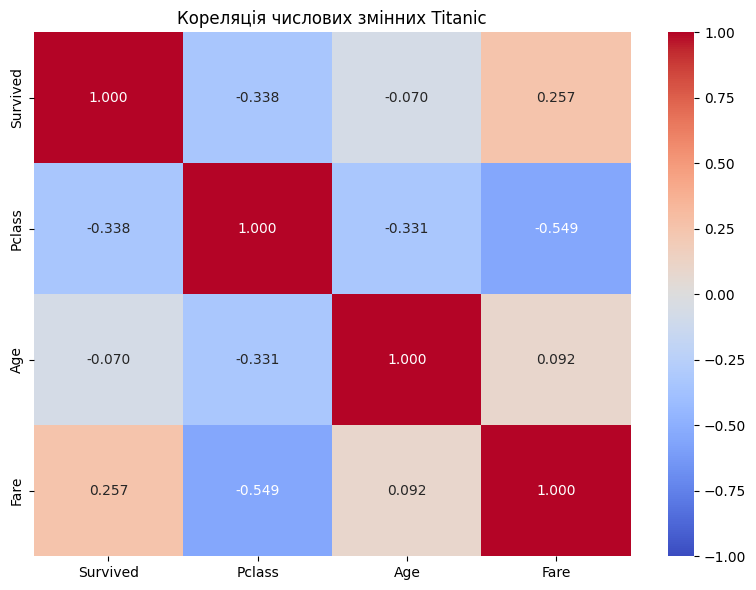

In [73]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_titanic,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)

plt.title("Кореляція числових змінних Titanic")
plt.tight_layout()
plt.show()

In [74]:
survival_correlations = (
    correlation_titanic["Survived"]
    .drop("Survived")
    .sort_values(key=abs, ascending=False)
)

print("Кореляція з виживанням:")
display(survival_correlations.to_frame("Кореляція"))

strongest_variable = survival_correlations.abs().idxmax()

print("\nНайсильніший лінійний зв'язок із виживанням має:")
print(strongest_variable)
print(
    "Коефіцієнт кореляції:",
    correlation_titanic.loc["Survived", strongest_variable]
)

Кореляція з виживанням:


,Кореляція
Pclass,-0.338481
Fare,0.257307
Age,-0.069809



Найсильніший лінійний зв'язок із виживанням має:
Pclass
Коефіцієнт кореляції: -0.33848103596101514


Висновок: Під час виконання другого завдання було проведено аналіз датасету Titanic за допомогою бібліотеки Pandas. Загальний рівень виживання склав 38,38%. При цьому жінки мали значно вищі шанси на порятунок (74,20%), ніж чоловіки (18,89%). Соціально-економічний статус також відіграв вирішальну роль: найвищий відсоток виживання зафіксовано у першому класі (62,96%), тоді як у другому він становив 47,28%, а в третьому — лише 24,24%. Саме клас пасажира має найсильнішу зворотну кореляцію з виживанням (-0,338), тобто перехід до нижчого класу суттєво зменшував шанси на порятунок. Відповідно, вартість квитка позитивно корелює з виживанням (0,257) і прямо залежить від класу обслуговування (середня ціна для першого класу — 84,15, для другого — 20,66, для третього — 13,68). Водночас вік мав мінімальний вплив на виживання (кореляція -0,070); середній вік загиблих становив 30,42 року, а врятованих — 28,55. Отже, результати підтверджують, що стать і клас пасажира були найважливішими чинниками виживання на «Титаніку». Виконання завдання дозволило успішно закріпити навички попередньої обробки даних, групування, обчислення статистичних показників, кореляційного аналізу та візуалізації.